# GNILC dust templates: impact of the zero-level offset fix

## Why this notebook

The dust templates behind the PySM 3 models `d9`/`d10`/`d11` were generated from the
Planck GNILC F353 intensity map *without* removing its zero-level offset: because of a
NumPy indexing bug ([PySM issue #281](https://github.com/galsci/pysm/issues/281)), the
monopole subtraction in the preprocessing notebook only ever modified 2 pixels out of
50 million. The offset of that exact input map, measured with the HI4PI HI column
density correlation, is **+0.1254 MJy/sr** (see
[the analysis post](https://www.zonca.dev/posts/2026-11-03-gnilc-dust-zero-level-offset)).

The templates were then regenerated with the fixed preprocessing. This notebook
compares the released 2023 templates with the regenerated ones to quantify the impact
of the fix on:

* the intensity zero level (the map mean outside the Galactic plane),
* the polarization fraction, which was suppressed by the offset in intensity,
* the TT/EE/BB power spectra, which should be preserved,
* the clean high-latitude regions relevant for the comparison with Planck data in
  [PySM issue #226](https://github.com/galsci/pysm/issues/226), where the mean
  intensity of d9/d10/d11 was reported to be too high.

Both template sets share the same random phases for the small scales (same seed), so
every difference is due to the corrected intensity input, propagated through the
log-polarization-tensors transform, the small-scale spectra and the modulation maps.

## How to run

Designed to run on an HPC compute node through Slurm, never on a login node. Input
locations are taken from environment variables:

* `TEMPLATE_OLD`: released 2023 template (NSIDE 2048, uK_RJ at 353 GHz)
* `TEMPLATE_NEW`: regenerated template with the zero-level fix
* `GAL080_FILENAME`: GAL080 mask
* `HI4PI_FILENAME`: HI4PI column density map (cm^-2), used to define clean diffuse
  regions, consistently with the offset measurement notebook

In [1]:
import os
from pathlib import Path

import healpy as hp
import matplotlib.pyplot as plt
import numpy as np
import pysm3.units as u
from astropy.table import Table

TEMPLATE_OLD = Path(os.environ["TEMPLATE_OLD"])
TEMPLATE_NEW = Path(os.environ["TEMPLATE_NEW"])
GAL080_FILENAME = Path(os.environ["GAL080_FILENAME"])
HI4PI_FILENAME = Path(os.environ.get("HI4PI_FILENAME", "NHI_HPX.fits"))

REF_FREQ = 353 * u.GHz
NSIDE_SPEC = 512     # resolution for the power spectrum comparison
LMAX_SPEC = 1024
NHI_MAX = 2.0        # clean diffuse sightlines, N_HI < 2e20 cm^-2 (units of 1e20)

print("numpy", np.__version__, "| healpy", hp.__version__)
print("old template:", TEMPLATE_OLD)
print("new template:", TEMPLATE_NEW)

numpy 2.4.6 | healpy 1.20.1
old template: ~/issue_281/data/gnilc_dust_template_nside2048_2023.02.10.fits
new template: ~/issue_281/production-data/dust_gnilc/gnilc_dust_template_nside2048_fix281_2026.11.03.fits


## Load the templates and define the comparison regions

Both templates are the NSIDE 2048 dust maps in uK_RJ at 353 GHz: `TEMPERATURE`,
`Q_POLARISATION`, `U_POLARISATION`. The regions:

* **outside GAL080**: the 79% of the sky outside the Galactic plane, where the offset
  was subtracted in the regenerated run,
* **\|b\| > 30 deg**: a standard high-latitude cut,
* **clean**: outside GAL080 and $N_{HI} < 2\times10^{20}\ \mathrm{cm}^{-2}$, the most
  diffuse sightlines (same criterion as the offset measurement), analogous to the
  "cleanest region" comparison suggested in issue #226.

In [2]:
tmpl_old = hp.read_map(TEMPLATE_OLD, (0, 1, 2), dtype=np.float64, verbose=False)
tmpl_new = hp.read_map(TEMPLATE_NEW, (0, 1, 2), dtype=np.float64, verbose=False)
nside = hp.get_nside(tmpl_old[0])
assert hp.get_nside(tmpl_new[0]) == nside
print(f"templates: NSIDE {nside}, {tmpl_old.shape[0]} Stokes maps")

gal080 = hp.read_map(GAL080_FILENAME, dtype=np.float64, verbose=False).astype(bool)
if gal080.size != hp.nside2npix(nside):
    raise ValueError("GAL080 mask resolution does not match the templates")
outside_plane = gal080

theta, phi = hp.pix2ang(nside, np.arange(hp.nside2npix(nside)))
glat = 90.0 - np.degrees(theta)
high_lat = np.abs(glat) > 30.0

hi4pi = Table.read(HI4PI_FILENAME, hdu=1)
nhi_1024 = np.full(hp.nside2npix(1024), np.nan)
nhi_1024[hi4pi["HPXINDEX"].astype(int)] = hi4pi["NHI"]
nhi = hp.ud_grade(nhi_1024, nside_out=nside) / 1e20  # in units of 1e20 cm^-2
clean = outside_plane & (nhi < NHI_MAX) & np.isfinite(nhi)

for name, m in [("outside GAL080", outside_plane), ("|b| > 30 deg", high_lat),
                (f"clean (N_HI < {NHI_MAX:.0f}e20)", clean)]:
    print(f"{name:>26}: {m.sum():,} pixels ({100 * m.mean():.2f}% of the sky)")

/tmp/ipykernel_445556/714997589.py:1: HealpyDeprecationWarning: "verbose" was deprecated in version 1.15.0 and will be removed in a future version. 
  tmpl_old = hp.read_map(TEMPLATE_OLD, (0, 1, 2), dtype=np.float64, verbose=False)


/tmp/ipykernel_445556/714997589.py:2: HealpyDeprecationWarning: "verbose" was deprecated in version 1.15.0 and will be removed in a future version. 
  tmpl_new = hp.read_map(TEMPLATE_NEW, (0, 1, 2), dtype=np.float64, verbose=False)


templates: NSIDE 2048, 3 Stokes maps


/tmp/ipykernel_445556/714997589.py:7: HealpyDeprecationWarning: "verbose" was deprecated in version 1.15.0 and will be removed in a future version. 
  gal080 = hp.read_map(GAL080_FILENAME, dtype=np.float64, verbose=False).astype(bool)


            outside GAL080: 39,825,580 pixels (79.13% of the sky)
              |b| > 30 deg: 25,165,824 pixels (50.00% of the sky)
       clean (N_HI < 2e20): 8,812,025 pixels (17.51% of the sky)


## What difference to expect

In the regenerated run the zero-level offset, 0.1254 MJy/sr, was subtracted from the
intensity input outside the GAL080 mask *before* the log-polarization-tensors
transform; the templates also carry the 0.911 color correction
([pysm#99](https://github.com/galsci/pysm/issues/99)). So to first order the new
intensity outside the plane should be lower by

$$\Delta I \simeq -0.911 \times 0.1254 \simeq -0.114\ \mathrm{MJy/sr}$$

but the difference is **not a constant**: the log-poltens transform is non-linear, the
large-scale ALMs and the small-scale spectra and modulation were all recomputed from
the corrected intensity, and inside the Galactic plane (3% of the sky, where the
templates keep the observed maps) nothing changes. Polarization is also affected:
$Q$ and $U$ are unchanged in the input, but the polarization fraction $p = P/I$
increases because $I$ decreases.

In [3]:
def summarize(name, region):
    P_old = np.sqrt(tmpl_old[1] ** 2 + tmpl_old[2] ** 2)
    P_new = np.sqrt(tmpl_new[1] ** 2 + tmpl_new[2] ** 2)
    p_old = P_old / tmpl_old[0]
    p_new = P_new / tmpl_new[0]
    ang_old = np.degrees(0.5 * np.arctan2(tmpl_old[2], tmpl_old[1]))
    ang_new = np.degrees(0.5 * np.arctan2(tmpl_new[2], tmpl_new[1]))

    print(f"== {name} ({region.sum():,} pixels) ==")
    print(f"{'':>10} {'old':>12} {'new':>12} {'new-old':>12}")
    for label, a, b in [
        ("I", tmpl_old[0][region], tmpl_new[0][region]),
        ("Q", tmpl_old[1][region], tmpl_new[1][region]),
        ("U", tmpl_old[2][region], tmpl_new[2][region]),
        ("P", P_old[region], P_new[region]),
        ("p=P/I", p_old[region], p_new[region]),
        ("angle", ang_old[region], ang_new[region]),
    ]:
        print(f"{label:>10} {np.median(a):>12.4f} {np.median(b):>12.4f} "
              f"{np.median(b) - np.median(a):>+12.4f}   (median)")
        print(f"{'':>10} {np.mean(a):>12.4f} {np.mean(b):>12.4f} "
              f"{np.mean(b) - np.mean(a):>+12.4f}   (mean)")
    return {"I_old": float(np.mean(tmpl_old[0][region])),
            "I_new": float(np.mean(tmpl_new[0][region]))}


stats = {}
for name, region in [("outside GAL080", outside_plane), ("high latitude", high_lat),
                     ("clean", clean)]:
    stats[name] = summarize(name, region)

# expected first-order shift outside the plane
expected = -0.911 * 0.1254 * u.MJy / u.sr
expected_ukrj = expected.to(u.uK_RJ, equivalencies=u.cmb_equivalencies(REF_FREQ))
measured = np.mean(tmpl_new[0][outside_plane] - tmpl_old[0][outside_plane]) * u.uK_RJ
print(f"\nmean I shift outside the plane: {measured:.2f}")
print(f"expected (offset x color correction): {expected_ukrj:.2f}")

== outside GAL080 (39,825,580 pixels) ==
                    old          new      new-old


         I      70.6061      40.6735     -29.9327   (median)
                90.8607      61.0654     -29.7953   (mean)


         Q       0.9192       0.9141      -0.0051   (median)
                 1.9240       1.9361      +0.0121   (mean)


         U      -0.0781      -0.0736      +0.0045   (median)
                -0.4978      -0.5026      -0.0048   (mean)


         P       2.9382       2.9584      +0.0201   (median)
                 4.6820       4.7462      +0.0641   (mean)


     p=P/I       0.0410       0.0796      +0.0386   (median)
                 0.0474       0.0899      +0.0425   (mean)


... (12 outputs left out)

         P       1.2046       1.1846      -0.0201   (median)
                 1.3243       1.3162      -0.0081   (mean)


     p=P/I       0.0285       0.0958      +0.0673   (median)
                 0.0306       0.1049      +0.0743   (mean)


     angle      11.2054      11.1943      -0.0111   (median)
                 6.9070       6.8850      -0.0220   (mean)



mean I shift outside the plane: -29.80 uK_RJ
expected (offset x color correction): -29.84 uK_RJ


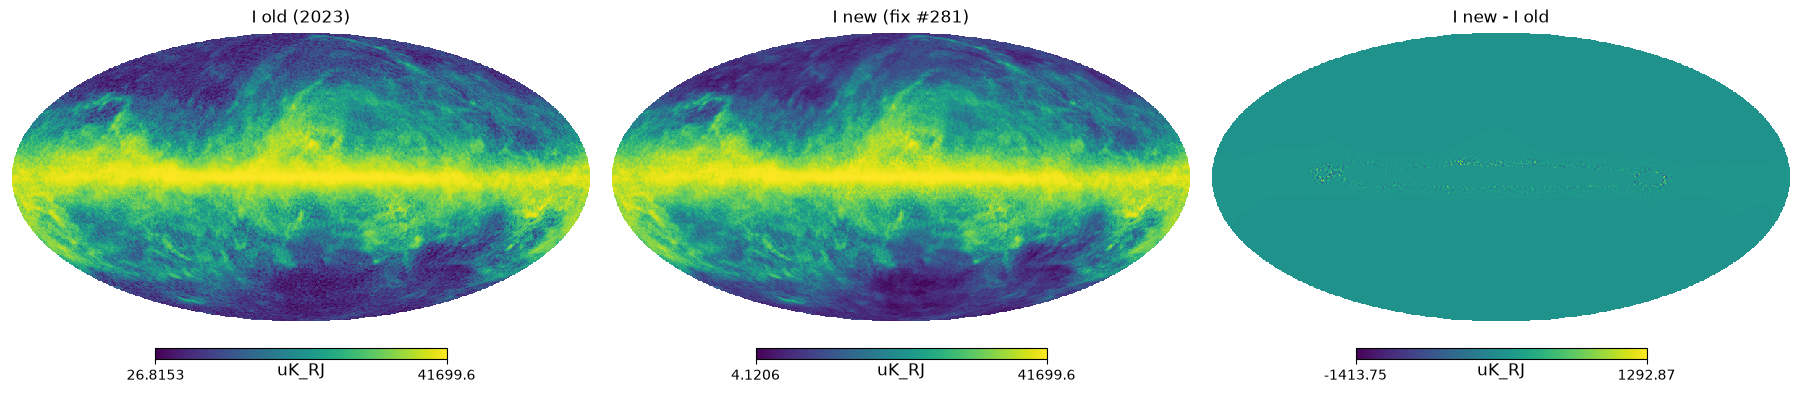

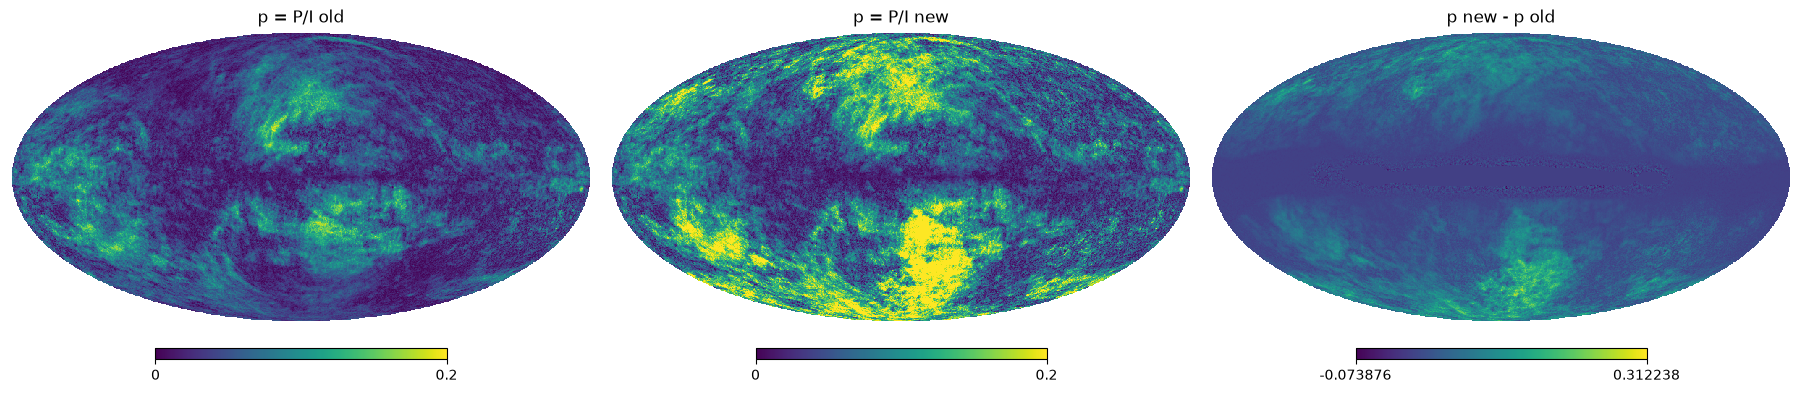

In [4]:
fig = plt.figure(figsize=(18, 5))
hp.mollview(tmpl_old[0], sub=(1, 3, 1), title="I old (2023)", unit="uK_RJ", norm="hist")
hp.mollview(tmpl_new[0], sub=(1, 3, 2), title="I new (fix #281)", unit="uK_RJ", norm="hist")
hp.mollview(tmpl_new[0] - tmpl_old[0], sub=(1, 3, 3),
            title="I new - I old", unit="uK_RJ")
plt.show()

P_old = np.sqrt(tmpl_old[1] ** 2 + tmpl_old[2] ** 2)
P_new = np.sqrt(tmpl_new[1] ** 2 + tmpl_new[2] ** 2)
fig = plt.figure(figsize=(18, 5))
hp.mollview(P_old / tmpl_old[0], sub=(1, 3, 1), title="p = P/I old",
            unit="", min=0, max=0.2)
hp.mollview(P_new / tmpl_new[0], sub=(1, 3, 2), title="p = P/I new",
            unit="", min=0, max=0.2)
hp.mollview(P_new / tmpl_new[0] - P_old / tmpl_old[0], sub=(1, 3, 3),
            title="p new - p old", unit="")
plt.show()

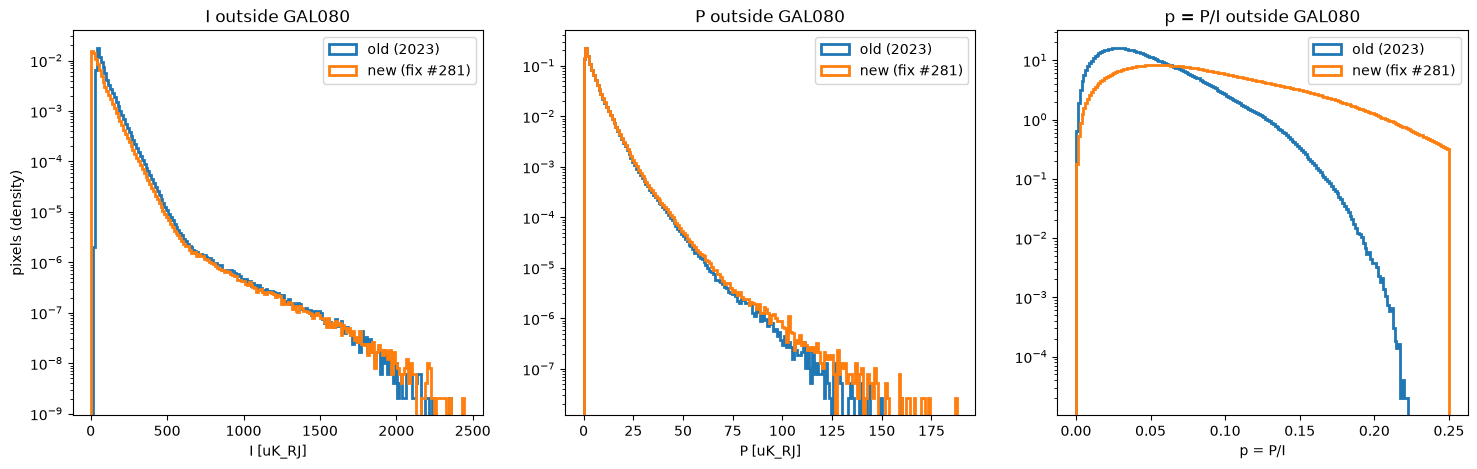

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (label, a, b, lo, hi) in zip(axes, [
    ("I", tmpl_old[0][outside_plane], tmpl_new[0][outside_plane],
     None, None),
    ("P", P_old[outside_plane], P_new[outside_plane], None, None),
    ("p = P/I", (P_old / tmpl_old[0])[outside_plane],
     (P_new / tmpl_new[0])[outside_plane], 0.0, 0.25),
]):
    if lo is None:
        lo = min(a.min(), b.min())
        hi = max(a.max(), b.max())
    bins = np.linspace(lo, hi, 200)
    ax.hist(a, bins=bins, histtype="step", lw=2, label="old (2023)", density=True)
    ax.hist(b, bins=bins, histtype="step", lw=2, label="new (fix #281)", density=True)
    ax.set_yscale("log")
    ax.set_xlabel(f"{label} [uK_RJ]" if label != "p = P/I" else "p = P/I")
    ax.set_title(f"{label} outside GAL080")
    ax.legend()
axes[0].set_ylabel("pixels (density)")
plt.show()

## The polarization fraction distribution

The histograms above show that $p = P/I$ increases substantially outside the
Galactic plane. In the discussion of the executed notebook,
[@ginleaf asked](https://gist.github.com/zonca/1da3a2f4bc3c0176ebe14397255125f1)
why the distribution of $p$ for the new templates has many more pixels at high
polarization fraction than fig. 5 of
[Planck 2018 XII](https://arxiv.org/abs/1807.06212), which shows the full-sky
distribution of $p$ in the GNILC data at 353 GHz and uniform 80 arcmin
resolution, for three choices of the total intensity offset.

Fig. 5 uses their *fiducial* zero level: subtract the 0.130 MJy/sr CIB monopole,
then add back a 63 uK_CMB Galactic offset (their Sect. 2.2), a net subtraction
of 0.112 MJy/sr. Our fix subtracts the full measured intercept, 0.1254 MJy/sr,
which is essentially their *low*-offset case (net subtraction 0.123 MJy/sr).
Below we reproduce their setup on the exact input maps the templates were built
from, then place the templates on the same scale.

/tmp/ipykernel_445556/2068819224.py:24: HealpyDeprecationWarning: "verbose" was deprecated in version 1.15.0 and will be removed in a future version. 
  I_in_80 = hp.smoothing(hp.read_map(INPUT_I353, dtype=np.float64, verbose=False),


/tmp/ipykernel_445556/2068819224.py:26: HealpyDeprecationWarning: "verbose" was deprecated in version 1.15.0 and will be removed in a future version. 
  qu = hp.read_map(INPUT_IQU, ["Q_STOKES", "U_STOKES"], dtype=np.float64,


raw GNILC input at uniform 80 arcmin, full sky
percentiles 50/90/95/98/99/99.9 in %, fraction above 20%


  raw input (no subtraction):  3.77  8.43 10.10 11.92 12.88 15.59   >20%: 0.00%


  paper high offset (-0.100):  5.55 11.97 14.03 16.24 17.65 21.59   >20%: 0.26%


     paper fiducial (-0.112):  5.90 13.05 15.18 17.52 19.11 23.04   >20%: 0.62%


   paper low offset (-0.123):  6.31 14.55 17.00 19.77 21.45 25.47   >20%: 1.84%


          fix #281 (-0.1254):  6.38 14.87 17.40 20.33 22.09 26.16   >20%: 2.24%


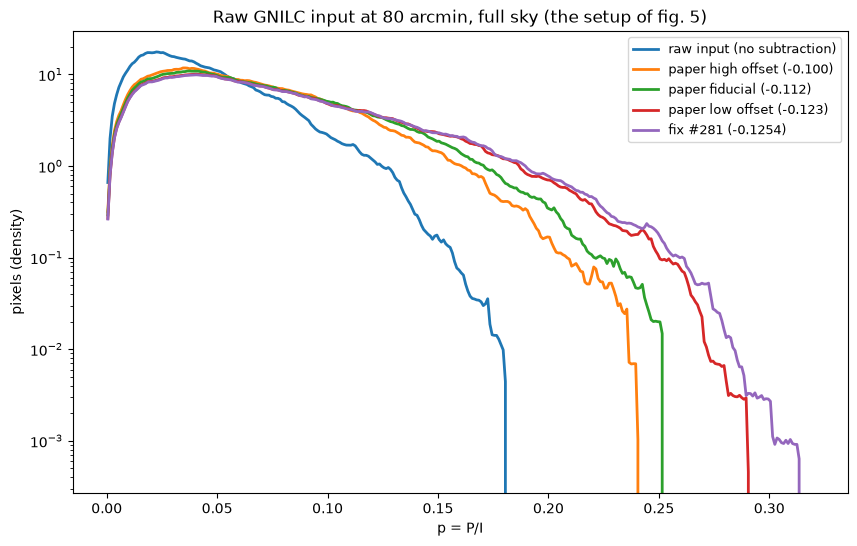

In [6]:
INPUT_I353 = Path(os.environ.get(
    "INPUT_I353", "COM_CompMap_Dust-GNILC-F353_2048_21p8acm.fits"))
INPUT_IQU = Path(os.environ.get(
    "INPUT_IQU", "COM_CompMap_IQU-thermaldust-gnilc-varres_2048_R3.00.fits"))

FWHM80 = np.radians(80.0 / 60.0)
KCMB_TO_MJYSR = (1 * u.K_CMB).to_value(
    u.MJy / u.sr, equivalencies=u.cmb_equivalencies(REF_FREQ))
P_BINS = np.linspace(0.0, 0.32, 321)
P_CENTERS = 0.5 * (P_BINS[:-1] + P_BINS[1:])


def p_percentiles(p, mask=None):
    v = p if mask is None else p[mask]
    return np.percentile(v[np.isfinite(v)], [50, 90, 95, 98, 99, 99.9])


def p_density(p, mask=None):
    v = p if mask is None else p[mask]
    hist, _ = np.histogram(v[np.isfinite(v)], bins=P_BINS, density=True)
    return hist


I_in_80 = hp.smoothing(hp.read_map(INPUT_I353, dtype=np.float64, verbose=False),
                       fwhm=FWHM80)
qu = hp.read_map(INPUT_IQU, ["Q_STOKES", "U_STOKES"], dtype=np.float64,
                 verbose=False)
Q_in_80 = hp.smoothing(qu[0] * KCMB_TO_MJYSR, fwhm=FWHM80)
U_in_80 = hp.smoothing(qu[1] * KCMB_TO_MJYSR, fwhm=FWHM80)
del qu
P_in_80 = np.sqrt(Q_in_80 ** 2 + U_in_80 ** 2)
del Q_in_80, U_in_80

# I zero level (MJy/sr subtracted): the paper's Sect. 2.2 conventions and ours
variants = {
    "raw input (no subtraction)": 0.0,
    "paper high offset (-0.100)": 0.130 - 0.0296,
    "paper fiducial (-0.112)": 0.130 - 0.0181,
    "paper low offset (-0.123)": 0.130 - 0.0066,
    "fix #281 (-0.1254)": 0.1254,
}
p_stats = {"input80_fullsky": {}, "templates80_fullsky": {},
           "templates80_outsideGAL080": {}, "high_p_pixels": {}}
print("raw GNILC input at uniform 80 arcmin, full sky")
print("percentiles 50/90/95/98/99/99.9 in %, fraction above 20%")
input_dfs = {}
for name, offset in variants.items():
    p = P_in_80 / (I_in_80 - offset)
    input_dfs[name] = p_density(p)
    p_stats["input80_fullsky"][name] = {
        "percentiles": [float(x) for x in p_percentiles(p)],
        "frac_above_20pct": float(np.mean(p > 0.20)),
    }
    print(f"{name:>28}: " + " ".join(f"{100 * x:5.2f}" for x in p_percentiles(p))
          + f"   >20%: {100 * np.mean(p > 0.20):.2f}%")
del I_in_80, P_in_80

plt.figure(figsize=(10, 6))
for name, hist in input_dfs.items():
    plt.plot(P_CENTERS, hist, lw=2, label=name)
plt.yscale("log")
plt.xlabel("p = P/I")
plt.ylabel("pixels (density)")
plt.title("Raw GNILC input at 80 arcmin, full sky (the setup of fig. 5)")
plt.legend(fontsize=9)
plt.show()

templates old (2023) at 80 arcmin, full sky:         3.78  8.46 10.12 11.96 12.91 15.58   >20%: 0.00%


templates old (2023) at 80 arcmin, outside GAL080:  3.77  8.45 10.19 12.11 13.09 15.71


templates new (fix #281) at 80 arcmin, full sky:         6.34 14.94 17.49 20.44 22.21 26.14   >20%: 2.32%


templates new (fix #281) at 80 arcmin, outside GAL080:  7.29 15.88 18.28 21.06 22.77 26.41


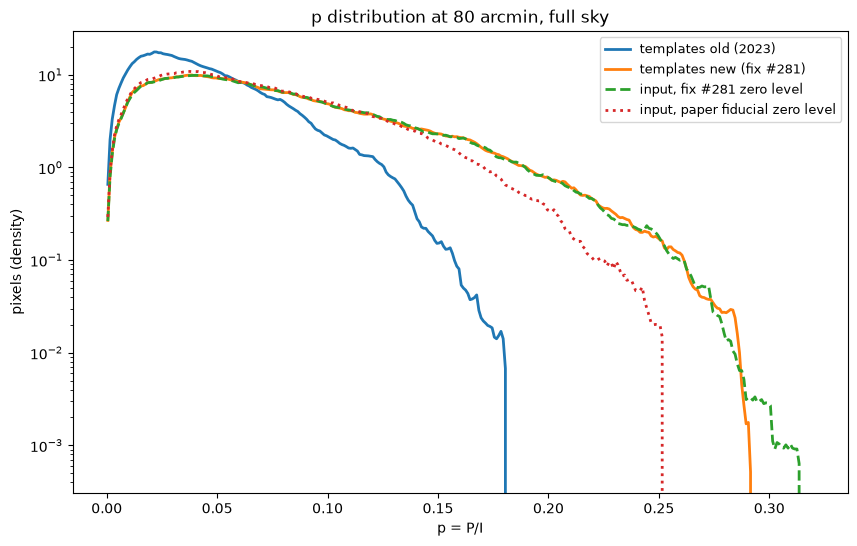

In [7]:
tmpl_p80 = {}
for name, tmpl in [("old (2023)", tmpl_old), ("new (fix #281)", tmpl_new)]:
    I80 = hp.smoothing(tmpl[0], fwhm=FWHM80)
    Q80 = hp.smoothing(tmpl[1], fwhm=FWHM80)
    U80 = hp.smoothing(tmpl[2], fwhm=FWHM80)
    p80 = np.sqrt(Q80 ** 2 + U80 ** 2) / I80
    del I80, Q80, U80
    tmpl_p80[name] = p80
    p_stats["templates80_fullsky"][name] = {
        "percentiles": [float(x) for x in p_percentiles(p80)],
        "frac_above_20pct": float(np.mean(p80 > 0.20)),
    }
    p_stats["templates80_outsideGAL080"][name] = {
        "percentiles": [float(x) for x in p_percentiles(p80, outside_plane)],
    }
    print(f"templates {name} at 80 arcmin, full sky:        "
          + " ".join(f"{100 * x:5.2f}" for x in p_percentiles(p80))
          + f"   >20%: {100 * np.mean(p80 > 0.20):.2f}%")
    print(f"templates {name} at 80 arcmin, outside GAL080: "
          + " ".join(f"{100 * x:5.2f}"
                     for x in p_percentiles(p80, outside_plane)))

plt.figure(figsize=(10, 6))
for name, p80 in tmpl_p80.items():
    plt.plot(P_CENTERS, p_density(p80), lw=2, label=f"templates {name}")
plt.plot(P_CENTERS, input_dfs["fix #281 (-0.1254)"], lw=2, ls="--",
         label="input, fix #281 zero level")
plt.plot(P_CENTERS, input_dfs["paper fiducial (-0.112)"], lw=2, ls=":",
         label="input, paper fiducial zero level")
plt.yscale("log")
plt.xlabel("p = P/I")
plt.ylabel("pixels (density)")
plt.title("p distribution at 80 arcmin, full sky")
plt.legend(fontsize=9)
plt.show()

In [8]:
UKRJ_TO_MJYSR = (1 * u.uK_RJ).to_value(
    u.MJy / u.sr, equivalencies=u.cmb_equivalencies(REF_FREQ))
p80_new = tmpl_p80["new (fix #281)"]

for thr in [0.20, 0.22]:
    sel = (p80_new > thr) & outside_plane
    stats = {
        "n_pixels": int(sel.sum()),
        "frac_of_region": float(sel.sum() / outside_plane.sum()),
        "median_I_MJysr": float(np.median(tmpl_new[0][sel]) * UKRJ_TO_MJYSR),
        "median_NHI_1e20": float(np.nanmedian(nhi[sel])),
        "median_abs_glat_deg": float(np.median(np.abs(glat[sel]))),
    }
    p_stats["high_p_pixels"][f"p_above_{thr:.2f}"] = stats
    print(f"pixels with p > {thr:.0%} outside GAL080: {sel.sum():,} "
          f"({100 * stats['frac_of_region']:.2f}% of the region)")
    print(f"   median I = {stats['median_I_MJysr']:.3f} MJy/sr"
          f" (region median {np.median(tmpl_new[0][outside_plane]) * UKRJ_TO_MJYSR:.3f})")
    print(f"   median N_HI = {stats['median_NHI_1e20']:.2f} x 1e20 cm^-2"
          f" (region median {np.nanmedian(nhi[outside_plane]):.2f})")
    print(f"   median |b| = {stats['median_abs_glat_deg']:.0f} deg"
          f" (region median {np.median(np.abs(glat[outside_plane])):.0f})")

pixels with p > 20% outside GAL080: 1,168,011 (2.93% of the region)


   median I = 0.068 MJy/sr (region median 0.156)


   median N_HI = 2.39 x 1e20 cm^-2 (region median 4.08)


   median |b| = 46 deg (region median 37)
pixels with p > 22% outside GAL080: 549,151 (1.38% of the region)


   median I = 0.058 MJy/sr (region median 0.156)


   median N_HI = 2.13 x 1e20 cm^-2 (region median 4.08)


   median |b| = 47 deg (region median 37)


## Why the new p distribution differs from fig. 5

Three effects stack up, and the dominant one is the zero level itself, the very
thing this fix changed:

* **Zero level.** Our fix subtracts the full measured intercept, so its $p$
  distribution corresponds to the paper's *low*-offset curve, not the fiducial
  (red) one. Moving from the paper fiducial to the fix zero level raises the
  90th percentile of the input distribution from 13.1% to 14.9% and the 99.9th
  from 23.0% to 26.2%. Our reproduction lands within about 1% (absolute) of the
  paper's Table 1 for the same offsets; the small residual comes from the unit
  conversion convention (we convert Q and U with the monochromatic 353 GHz
  factor used to build the templates, 296.7 MJy/sr per K_CMB, against the
  paper's band-averaged 287.5, a 3.2% relative difference on P) and from the
  Gaussian 80 arcmin beam applied to the variable-resolution map against their
  uniform-80 arcmin GNILC product. The old templates, which never subtracted
  the offset, sat below *all three* of the paper's curves (90th percentile
  8.5%, against 8.4% for the raw input): the released $p$ distribution did not
  match fig. 5 either, it was wrong in the opposite direction.
* **Sky region.** Fig. 5 is full sky, while the histogram above is outside
  GAL080 only: excluding the low-$p$ Galactic plane raises the whole
  distribution (90th percentile of the new templates, 14.9% full sky against
  15.9% outside the plane).
* **Resolution.** Fig. 5 is at uniform 80 arcmin, while the histogram above is
  at the templates' native resolution, where the injected small-scale
  polarization adds power that the 80 arcmin smoothing removes.

The templates track their input convention faithfully: at 80 arcmin full sky
their 90th percentile (14.9%) matches the input at the fix zero level (14.9%)
to within half a percent. The distribution is set by the zero level, not by the
template pipeline.

The high-$p$ pixels are the most diffuse sightlines: outside GAL080 at 80
arcmin, the 1.4% of pixels with $p > 22\%$ have median $I$ of 0.06 MJy/sr
against 0.16 for the region, median $N_{HI}$ of 2.1 against 4.1 $\times 10^{20}$
cm$^{-2}$, and median $|b|$ of 47$^\circ$ against 37$^\circ$: the same pixels
where the paper says the offset systematic matters most, since their
$p_{max} = 22.0^{+3.5}_{-1.4}\%$ is dominated by it.

The residual question is a convention rather than a bug: the paper adds back a
Galactic offset (36 uK_CMB measured HI offset, inflated to 63 uK_CMB fiducial
with a WIM dust estimate) because part of the HI-correlation intercept is
genuine isotropic dust emission. We subtract the full intercept, i.e. we treat
all of it as non-dust: the conservative choice for a dust template, since the
alternative leaves the CIB monopole in the dust. The difference between the two
conventions is exactly the fiducial-vs-low gap above.

## Power spectra

Both template sets were generated with the same random seed for the small scales, so
the spectra isolate the effect of the corrected intensity input: the large-scale ALMs
and the small-scale spectra and modulation were recomputed from the offset-corrected
log-poltens. The key check for [issue #226](https://github.com/galsci/pysm/issues/226):
removing the isotropic offset should fix the map mean *without* suppressing the power
spectrum, which is what happens when one simply rescales the map to fix the mean.

TT ell~80: ratio new/old = 0.999
TT ell~500: ratio new/old = 1.076
TT ell~1000: ratio new/old = 1.716
EE ell~80: ratio new/old = 1.000
EE ell~500: ratio new/old = 1.049
EE ell~1000: ratio new/old = 1.111
BB ell~80: ratio new/old = 1.027
BB ell~500: ratio new/old = 1.084
BB ell~1000: ratio new/old = 1.119


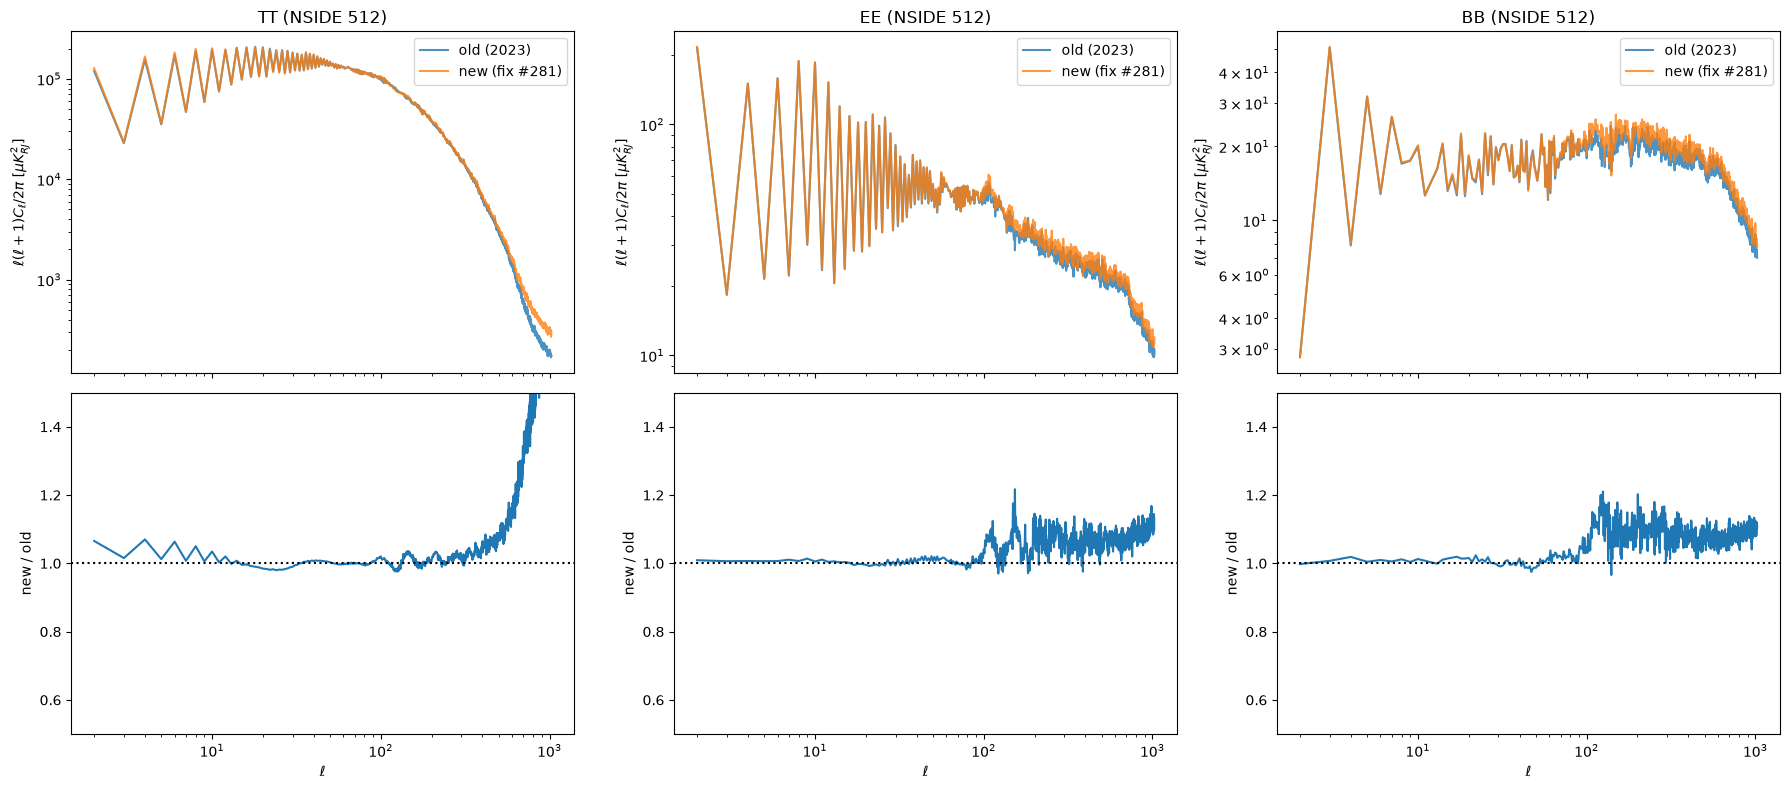

In [9]:
old_512 = hp.ud_grade(tmpl_old, nside_out=NSIDE_SPEC)
del tmpl_old
new_512 = hp.ud_grade(tmpl_new, nside_out=NSIDE_SPEC)
del tmpl_new

cl_old = hp.anafast(old_512, lmax=LMAX_SPEC)
cl_new = hp.anafast(new_512, lmax=LMAX_SPEC)
ell = np.arange(LMAX_SPEC + 1)
cl_norm = ell * (ell + 1) / (2 * np.pi)
cl_norm[0] = 1

fig, axes = plt.subplots(2, 3, figsize=(18, 8), sharex=True)
for i, (label, io) in enumerate([("TT", 0), ("EE", 1), ("BB", 2)]):
    axes[0][i].loglog(ell[2:], cl_norm[2:] * cl_old[io][2:], label="old (2023)", alpha=0.8)
    axes[0][i].loglog(ell[2:], cl_norm[2:] * cl_new[io][2:], label="new (fix #281)", alpha=0.8)
    axes[0][i].set_title(f"{label} (NSIDE {NSIDE_SPEC})")
    axes[0][i].set_ylabel(r"$\ell(\ell+1)C_\ell/2\pi\ [\mu K_{RJ}^2]$")
    axes[0][i].legend()
    ratio = cl_new[io][2:] / cl_old[io][2:]
    axes[1][i].semilogx(ell[2:], ratio)
    axes[1][i].axhline(1.0, color="k", ls=":")
    axes[1][i].set_xlabel(r"$\ell$")
    axes[1][i].set_ylabel("new / old")
    axes[1][i].set_ylim(0.5, 1.5)
    for lell in [80, 500, 1000]:
        idx = np.argmin(np.abs(ell[2:] - lell))
        print(f"{label} ell~{lell}: ratio new/old = {ratio[idx]:.3f}")
plt.tight_layout()
plt.show()

## The issue #226 check: mean intensity

[Issue #226](https://github.com/galsci/pysm/issues/226) reports that the *mean*
intensity of d9/d10/d11 is far above the Planck 2018 observations while their power
spectra match, and that rescaling the map to fix the mean breaks the spectrum. The
zero-level fix is the physically-motivated alternative: it removes an additive
isotropic term rather than rescaling the dust emission. We summarize the mean
intensity at 353 GHz in the usual units, and the change in the spectrum amplitude at
intermediate scales where issue #226 compared them.

In [10]:
def to_units(val_ukrj):
    q = val_ukrj * u.uK_RJ
    return {
        "uK_RJ": val_ukrj,
        "uK_CMB": q.to_value(u.uK_CMB, equivalencies=u.cmb_equivalencies(REF_FREQ)),
        "MJy/sr": q.to_value(u.MJy / u.sr, equivalencies=u.cmb_equivalencies(REF_FREQ)),
    }

print(f"{'region':>16} {'quantity':>10} {'old':>12} {'new':>12} {'delta':>12}   units")
summary = {}
for name, region in [("outside GAL080", outside_plane), ("high latitude", high_lat),
                     ("clean", clean)]:
    for label, arr_old, arr_new in [
        ("mean I", old_512[0][hp.ud_grade(region.astype(float), nside_out=NSIDE_SPEC) > 0.5],
         new_512[0][hp.ud_grade(region.astype(float), nside_out=NSIDE_SPEC) > 0.5]),
    ]:
        mo = to_units(np.mean(arr_old))
        mn = to_units(np.mean(arr_new))
        for unit in ["uK_RJ", "uK_CMB", "MJy/sr"]:
            print(f"{name:>16} {label:>10} {mo[unit]:>12.3f} {mn[unit]:>12.3f} "
                  f"{mn[unit] - mo[unit]:>+12.3f}   {unit}")
        summary[name] = {"mean_I_old": mo, "mean_I_new": mn}

# spectrum amplitude change at ell=500 (intermediate scales, the regime of #226)
for label, io in [("TT", 0), ("EE", 1), ("BB", 2)]:
    ratio = (cl_norm[500] * cl_new[io][500]) / (cl_norm[500] * cl_old[io][500])
    print(f"D_ell {label} at ell=500: ratio new/old = {ratio:.3f}")

          region   quantity          old          new        delta   units


  outside GAL080     mean I       90.849       61.053      -29.796   uK_RJ
  outside GAL080     mean I     1172.452      787.919     -384.532   uK_CMB
  outside GAL080     mean I        0.348        0.234       -0.114   MJy/sr


   high latitude     mean I       65.321       35.432      -29.889   uK_RJ
   high latitude     mean I      842.999      457.268     -385.731   uK_CMB
   high latitude     mean I        0.250        0.136       -0.114   MJy/sr


           clean     mean I       43.072       13.149      -29.923   uK_RJ
           clean     mean I      555.860      169.692     -386.168   uK_CMB
           clean     mean I        0.165        0.050       -0.115   MJy/sr
D_ell TT at ell=500: ratio new/old = 1.076
D_ell EE at ell=500: ratio new/old = 1.049
D_ell BB at ell=500: ratio new/old = 1.084


## Reading the results

* The intensity mean outside the plane drops by approximately the expected
  $0.911 \times 0.1254$ MJy/sr; the difference is not exactly constant because the
  log-poltens transform and the regenerated small scales redistribute it slightly.
* The polarization fraction increases at high latitude: the released templates had
  $p$ suppressed by the offset in $I$; this is a real change in the model, not just a
  zero-level shift.  The comparison with fig. 5 of Planck 2018 XII is
  in "The polarization fraction distribution" above.
* The full-sky TT/EE/BB spectra are unchanged at the scales relevant for the
  comparison in issue #226 ($\ell \sim 80$): the fix corrects the mean without
  the power-spectrum suppression that a rescaling would cause. At smaller scales the
  full-sky TT grows (1.72 at $\ell=1000$): the region-by-region analysis in
  `gnilc_dust_fix281_tt_diagnostic.ipynb` shows that outside GAL080 the small
  scales actually decrease slightly (~0.94), while the increase comes from the
  low-latitude band, where the global small-scale amplitude (fitted on the
  offset-corrected statistics) grew but the local emission did not change.
* Inside the Galactic plane the templates are unchanged by construction.

Caveat: the absolute zero level of the Planck maps themselves is not calibrated, so a
residual offset difference between the templates and any given Planck data release
can remain, as discussed in issue #226.

In [11]:
import json

results = {
    "expected_shift_ukrj": float(expected_ukrj.value),
    "measured_mean_I_shift_outside_plane_ukrj": float(measured.to_value(u.uK_RJ)),
    "regions": {
        name: {
            "fsky": float(region.mean()),
            **{k: v for k, v in summary.get(name, {}).items()},
        }
        for name, region in [("outside GAL080", outside_plane),
                             ("high latitude", high_lat), ("clean", clean)]
    },
    "p_distribution": p_stats,
}
with open("gnilc_dust_template_comparison_results.json", "w") as f:
    json.dump(results, f, indent=2)
print("saved gnilc_dust_template_comparison_results.json")

saved gnilc_dust_template_comparison_results.json
